# Vibration-Based Bearing Fault Detection for a Centrifuge

AI/ML Engineer assignment: exploratory data analysis (Q1) and modelling (Q2).

**Held-out data rule.** The brief reserves **29 April to 9 June 2025** as the evaluation period ("not provided to you"),
but the supplied file contains data for those dates. To respect the brief, the file is split at load time:

- `dev`: everything **before 29 April 2025**. All exploration, feature selection, training and threshold setting use only this.
- `holdout`: **29 April to 9 June 2025**. Touched once, in the final section, after the model is frozen.

**Labels.** The brief labels **1 to 4 January 2025** as a bearing fault (the date was corrected by annotation in the PDF from
an earlier 1 to 4 April). That is the only labelled fault inside `dev`.

**Contents**
1. Setup and held-out split
2. Data structure, record types and units
3. Operating states
4. Vibration trend and the labelled fault
5. Periods and labels
6. Spectral, velocity and envelope analysis; which waveform streams the model uses
7. Feature engineering and exploratory projections
8. Feature selection
9. Bearing Health Index and anomaly model
10. Model comparison (anomaly detection, incl. k-NN health index, vs supervised)
11. Feature importance
12. Explainability
13. Robustness check
14. Final evaluation on the held-out period

## 1. Setup and held-out split

In [4]:
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import hilbert

from utils import preprocess_acceleration, preprocess_velocity, get_fft, bandpass_filter
import bearing_model as bm
importlib.reload(bm)

pd.set_option("display.width", 160)
# Report style: ggplot look, drawn at page width (6.5 in) so text stays readable in the PDF
plt.style.use("ggplot")
plt.rcParams.update({
    "figure.figsize": (6.5, 3.0), "figure.dpi": 110,
    "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 7.5,
    "lines.linewidth": 0.9,
    "date.converter": "concise",          # short, non-overlapping date labels
    "axes.facecolor": "#F4F4F4",          # very light grey panel (ggplot default is #E5E5E5)
    "legend.facecolor": "#F4F4F4",
    "grid.color": "white", "grid.linewidth": 1.0,
})

# Report palette
BLUSH, PINK, ROSE, PURPLE, BLUE, NAVY = "#F39898", "#7A303F", "#F2482E", "#A155B9", "#165BAA", "#0B1354"
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=[BLUE, ROSE, PURPLE, NAVY, PINK])
WARN_C, ALARM_C = PURPLE, ROSE                     # threshold lines and statuses, used in every chart
STATUS_C = {"normal": BLUE, "warning": WARN_C, "alarm": ALARM_C}

DATA_PATH = "centrifuge line datasets.parquet"
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

HOLDOUT_START = pd.Timestamp("2025-04-29", tz="UTC")
LABEL_START = pd.Timestamp("2025-01-01", tz="UTC")
LABEL_END = pd.Timestamp("2025-01-04 23:00", tz="UTC")   # per the brief: 1 Jan 00:00 - 4 Jan 23:00

HF = bm.HF_COL                                     # Z short wave, high frequency (51.2 kHz)
LF = bm.LF_COL                                     # Z short wave, low frequency (5.12 kHz)
LW = "Motor DE_Z Long Wave High Frequency"         # Z long wave, high frequency (51.2 kHz, 2.56 s)
RMS_COL = "Motor DE_Z Short Wave High Frequency RMS"

def save_fig(name):
    for ext in ("png", "pdf"):                     # PNG for viewing, PDF (vector) for the report
        plt.savefig(FIG_DIR / f"{name}.{ext}")

In [5]:
raw = pd.read_parquet(DATA_PATH)
raw["date"] = pd.to_datetime(raw["date"], utc=True)
raw = raw.sort_values("date").reset_index(drop=True)
print(f"{len(raw):,} rows | {raw['date'].min()} -> {raw['date'].max()}")

# Split ONCE, here. Everything up to section 14 uses `dev` only.
is_holdout = raw["date"] >= HOLDOUT_START
dev = raw.loc[~is_holdout].reset_index(drop=True)
holdout = raw.loc[is_holdout].reset_index(drop=True)
assert dev["date"].max() < HOLDOUT_START <= holdout["date"].min()

print(f"dev:     {len(dev):,} rows ({dev['date'].min():%d %b} -> {dev['date'].max():%d %b %Y})")
print(f"holdout: {len(holdout):,} rows ({holdout['date'].min():%d %b} -> {holdout['date'].max():%d %b %Y}) "
      f"= {is_holdout.mean():.0%} of the file, set aside until section 14")

26,502 rows | 2025-01-01 00:00:00+00:00 -> 2025-06-09 23:59:58+00:00
dev:     15,979 rows (01 Jan -> 28 Apr 2025)
holdout: 10,523 rows (29 Apr -> 09 Jun 2025) = 40% of the file, set aside until section 14


## 2. Data structure, record types and units

The column, type and sampling-rate table in the brief is misaligned with the column names, so sampling rates are inferred
from snapshot lengths: each length divided by 2.56 gives a whole number of spectral lines (the standard analyser setting).

In [6]:
WAVE_FS = {HF: 51200, LW: 51200, LF: 5120,
           "Motor DE_X Short Wave Low Frequency": 4001, "Motor DE_Y Short Wave Low Frequency": 4001,
           "Motor DE_Audio Signal": 11025}
rows = []
for col, fs in WAVE_FS.items():
    s = dev[col].dropna()
    s = s[s.apply(bm._is_waveform)]
    n = len(s.iloc[0]) if len(s) else np.nan
    rows.append({"channel": col.replace("Motor DE_", ""), "snapshots": len(s), "samples": n,
                 "fs_hz": fs, "duration_s": round(n / fs, 2), "lines": n / 2.56, "fmax_hz": round(fs / 2.56)})
print(pd.DataFrame(rows).to_string(index=False))

scalars = dev.select_dtypes("number")
print("\nScalar channels (dev):")
print(scalars.describe().T[["count", "mean", "50%", "max"]].round(3))

                    channel  snapshots  samples  fs_hz  duration_s   lines  fmax_hz
Z Short Wave High Frequency       1968    16384  51200        0.32  6400.0    20000
 Z Long Wave High Frequency        452   131072  51200        2.56 51200.0    20000
 Z Short Wave Low Frequency       1965     9216   5120        1.80  3600.0     2000
 X Short Wave Low Frequency       1967     5120   4001        1.28  2000.0     1563
 Y Short Wave Low Frequency       1970     5120   4001        1.28  2000.0     1563
               Audio Signal        450   131072  11025       11.89 51200.0     4307

Scalar channels (dev):
                                            count    mean    50%     max
Motor DE_Z Short Wave Low Frequency RMS    2018.0   1.296  0.104   6.573
Motor DE_X Short Wave Low Frequency RMS      55.0   0.021  0.020   0.063
Motor DE_Y Short Wave Low Frequency RMS      53.0   0.022  0.021   0.073
Motor DE_Z Speed Total Value                397.0   1.134  0.292   8.529
Motor DE_X Speed Total 

In [8]:
sec = dev["date"].dt.second
has_hf = dev[HF].apply(bm._is_waveform)
has_rms = dev[RMS_COL].notna()

print(pd.crosstab(sec, has_hf))
print(pd.crosstab(sec, has_rms))

Motor DE_Z Short Wave High Frequency  False  True 
date                                              
0                                        34   1968
20                                    11110      0
21                                      944      0
58                                     1921      0
59                                        2      0
Motor DE_Z Short Wave High Frequency RMS  False  True 
date                                                  
0                                          1990     12
20                                         1037  10073
21                                           58    886
58                                         1521    400
59                                            1      1


In [7]:
# Two record types, distinguished by the seconds field of the timestamp
sec = dev["date"].dt.second
dev["record_type"] = np.select([sec.isin([20, 21]), sec.isin([0, 1, 58, 59])], ["summary", "waveform"], "other")
has_wave = dev[HF].apply(bm._is_waveform)
print(pd.crosstab(dev["record_type"], has_wave.rename("has HF waveform")))

has HF waveform  False  True 
record_type                  
summary          12054      0
waveform          1957   1968


In [5]:
# Waveform snapshots with running state and run structure (computed once, reused below)
snap = bm.steady_snapshots(dev)
print(f"{len(snap)} waveform snapshots | running: {snap['running'].sum()} | steady (past 3 h warm-up): {snap['steady'].sum()}")

# Units: stored RMS vs RMS recomputed from the waveform in the same record
both = snap[snap["running"] & snap[RMS_COL].notna()]
ratio = both["wf_rms"] / both[RMS_COL]
print(f"\nWaveform RMS / stored RMS (running, n={len(both)}): median {ratio.median():.3f}, IQR {ratio.quantile(.25):.3f}-{ratio.quantile(.75):.3f}")
print("-> same scale, no factor of 1,000: units are m/s^2 (the brief says mm/s^2)")
vel = dev["Motor DE_Z Speed Total Value"].dropna()
print(f"Stored velocity ('Speed Total Value'): median {vel.median():.2f}, max {vel.max():.2f} mm/s -> realistic only for m/s^2 input")

1968 waveform snapshots | running: 757 | steady (past 3 h warm-up): 699

Waveform RMS / stored RMS (running, n=3): median 1.060, IQR 1.052-1.077
-> same scale, no factor of 1,000: units are m/s^2 (the brief says mm/s^2)
Stored velocity ('Speed Total Value'): median 0.29, max 8.53 mm/s -> realistic only for m/s^2 input


## 3. Operating states

The machine is stopped much of the time. Mixing stopped and running data would teach a model *on vs off* rather than
*healthy vs faulty*, so all fault analysis uses steady running only.

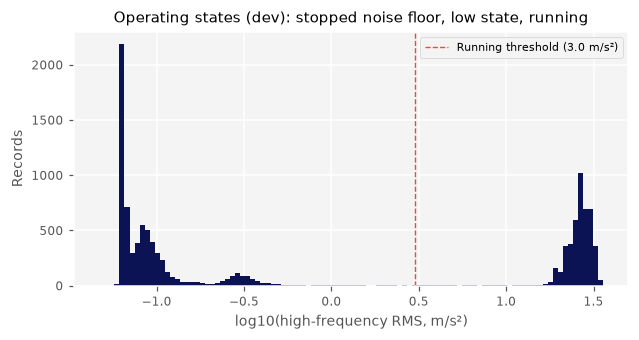

In [6]:
vals = dev[RMS_COL].dropna()
vals = vals[vals > 0]
fig, ax = plt.subplots(figsize=(6.5, 3.0))
ax.hist(np.log10(vals), bins=100, color=NAVY)
ax.axvline(np.log10(bm.RUNNING_THR), c=ROSE, ls="--", label=f"Running threshold ({bm.RUNNING_THR} m/s²)")
ax.set_xlabel("log10(high-frequency RMS, m/s²)"); ax.set_ylabel("Records")
ax.set_title("Operating states (dev): stopped noise floor, low state, running")
ax.legend(); save_fig("fig_states_hist"); plt.show()

## 4. Vibration trend and the labelled fault

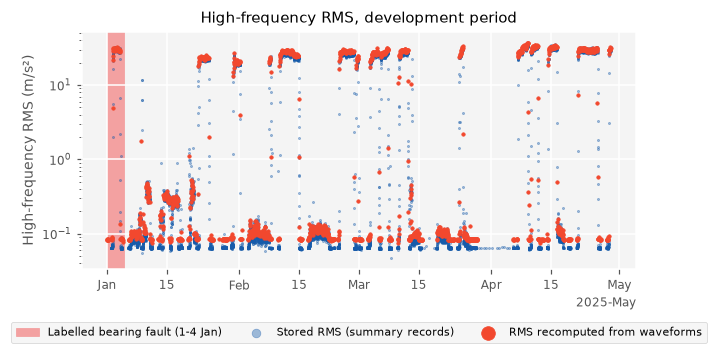

In [7]:
summary = dev[(dev["record_type"] == "summary") & dev[RMS_COL].notna()]
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.axvspan(LABEL_START, LABEL_END, color=BLUSH, alpha=0.9, zorder=0,          # behind the points
           label="Labelled bearing fault (1-4 Jan)")
ax.scatter(summary["date"], summary[RMS_COL], s=2, alpha=0.4, zorder=2,
           label="Stored RMS (summary records)")
ax.scatter(snap["date"], snap["wf_rms"], s=5, c=ROSE, zorder=3,
           label="RMS recomputed from waveforms")
ax.set_yscale("log"); ax.set_ylabel("High-frequency RMS (m/s²)")
ax.set_title("High-frequency RMS, development period")
ax.legend(markerscale=4, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2))
save_fig("fig_trend"); plt.show()

In [8]:
# Runs (consecutive running snapshots) and their vibration level
run = snap[snap["running"]]
runs = run.groupby("run_id").agg(start=("date", "min"), end=("date", "max"), snapshots=("date", "size"),
                                 median_rms=("wf_rms", "median"))
runs["hours"] = ((runs["end"] - runs["start"]).dt.total_seconds() / 3600).round(1)
print(runs.round(2).to_string())

# Agreement on running state between summary records and waveforms (hourly)
ra = (summary.set_index("date")[RMS_COL] > bm.RUNNING_THR).resample("1h").max()
rw = (snap.set_index("date")["wf_rms"] > bm.RUNNING_THR).resample("1h").max()
j = pd.concat({"summary": ra, "waveform": rw}, axis=1).dropna()
print(f"\nRunning-state agreement, summary vs waveform: {(j['summary'] == j['waveform']).mean():.1%} of {len(j)} hours")

                           start                       end  snapshots  median_rms  hours
run_id                                                                                  
0.0    2025-01-02 07:00:00+00:00 2025-01-04 01:00:00+00:00         41       30.21   42.0
1.0    2025-01-22 05:00:00+00:00 2025-01-22 05:00:00+00:00          1       17.88    0.0
2.0    2025-01-22 11:00:00+00:00 2025-01-24 12:00:00+00:00         48       23.43   49.0
3.0    2025-01-24 15:00:00+00:00 2025-01-24 19:00:00+00:00          4       23.23    4.0
4.0    2025-01-30 13:00:00+00:00 2025-02-01 04:00:00+00:00         36       20.22   39.0
5.0    2025-02-08 00:00:00+00:00 2025-02-08 07:00:00+00:00          8       21.73    7.0
6.0    2025-02-10 09:00:00+00:00 2025-02-10 15:00:00+00:00          7       23.55    6.0
7.0    2025-02-10 18:00:00+00:00 2025-02-14 21:00:00+00:00         96       27.72   99.0
8.0    2025-02-24 09:00:00+00:00 2025-02-27 18:00:00+00:00         82       27.89   81.0
9.0    2025-02-28 09:

/var/folders/v4/k36gcvns0md4h5rqd_bd41k80000gn/T/ipykernel_67019/132683205.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(runs.round(2).to_string())
/var/folders/v4/k36gcvns0md4h5rqd_bd41k80000gn/T/ipykernel_67019/132683205.py:11: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  j = pd.concat({"summary": ra, "waveform": rw}, axis=1).dropna()


In [9]:
# Prepare held-out waveform snapshots
snap_h = bm.steady_snapshots(holdout)

# Summary records at seconds 20–21 with available reported RMS
summary_h = holdout.loc[
    holdout["date"].dt.second.isin([20, 21])
    & holdout[RMS_COL].notna()
]

# Runs and their waveform-calculated vibration level
run_h = snap_h.loc[snap_h["running"]]

runs_h = run_h.groupby("run_id").agg(
    start=("date", "min"),
    end=("date", "max"),
    snapshots=("date", "size"),
    median_rms=("wf_rms", "median"),
)

runs_h["hours"] = (
    (runs_h["end"] - runs_h["start"]).dt.total_seconds() / 3600
).round(1)

print(runs_h.round({"median_rms": 2}).to_string())

# Hourly running-state agreement: reported vs calculated RMS
ra_h = (
    summary_h.set_index("date")[RMS_COL] > bm.RUNNING_THR
).resample("1h").max()

rw_h = (
    snap_h.set_index("date")["wf_rms"] > bm.RUNNING_THR
).resample("1h").max()

j_h = pd.concat(
    {"summary": ra_h, "waveform": rw_h},
    axis=1,
    sort=True,
).dropna()

if len(j_h):
    agreement_h = (j_h["summary"] == j_h["waveform"]).mean()
    print(
        f"\nHeld-out running-state agreement, summary vs waveform: "
        f"{agreement_h:.1%} of {len(j_h)} hours"
    )
else:
    print("\nNo overlapping hours available for comparison.")

                           start                       end  snapshots  median_rms  hours
run_id                                                                                  
0.0    2025-04-29 00:00:00+00:00 2025-04-30 16:00:00+00:00         41       30.58   40.0
1.0    2025-05-02 08:00:00+00:00 2025-05-03 02:00:00+00:00         19       32.25   18.0
2.0    2025-05-13 03:00:00+00:00 2025-05-16 20:00:00+00:00         90       33.61   89.0
3.0    2025-05-26 10:00:00+00:00 2025-05-28 18:00:00+00:00         56       34.83   56.0
4.0    2025-05-30 05:00:00+00:00 2025-05-31 10:00:00+00:00         30       29.83   29.0
5.0    2025-06-01 03:00:00+00:00 2025-06-05 17:00:00+00:00        111       30.43  110.0

Held-out running-state agreement, summary vs waveform: 99.1% of 644 hours


**Reading.** The labelled fault (1 to 4 January) is a running period with fault-level vibration. It is followed by a long
stop and a restart whose level settles down over the first run (a run-in pattern, consistent with a repair). Runs from late
January to mid-March are steady and healthy. Vibration rises again from late March, through April.

## 5. Periods and labels

| Split | Period | Label | Used for |
| --- | --- | --- | --- |
| `labelled_fault` | 1-4 Jan | **Bearing fault (brief)** | Alarm threshold; supervised training |
| `train` | 5 Jan - 28 Feb | Healthy (inferred) | Fit baselines and models |
| `val_healthy` | 1-13 Mar | Healthy (inferred) | Warning threshold; false-alarm rate |
| `onset` | 14-31 Mar | Unlabelled | Descriptive |
| `april_inferred` | 1-28 Apr | Fault (inferred, not labelled) | Independent check on a second episode |
| `heldout` | 29 Apr - 9 Jun | Bearing fault (brief) | **Section 14 only** |

In [9]:
SPLIT_EDGES = [(LABEL_END, "labelled_fault"),
               (pd.Timestamp("2025-03-01", tz="UTC"), "train"),
               (pd.Timestamp("2025-03-14", tz="UTC"), "val_healthy"),
               (pd.Timestamp("2025-04-01", tz="UTC"), "onset"),
               (HOLDOUT_START, "april_inferred")]
ORDER = ["labelled_fault", "train", "val_healthy", "onset", "april_inferred"]
COLORS = {"labelled_fault": ROSE, "train": BLUE, "val_healthy": NAVY,
          "onset": PINK, "april_inferred": PURPLE, "heldout": "#555555"}
SPLIT_LABEL = {"labelled_fault": "labelled fault (1-4 Jan)", "train": "train (Jan-Feb)",
               "val_healthy": "healthy validation (1-13 Mar)", "onset": "onset (14-31 Mar)",
               "april_inferred": "inferred fault (1-28 Apr)", "heldout": "held-out (29 Apr-9 Jun)"}

def split_of(t):
    for edge, name in SPLIT_EDGES:
        if t <= edge if name == "labelled_fault" else t < edge:
            return name
    return "heldout"

steady = snap[snap["steady"]].copy()
steady["split"] = steady["date"].apply(split_of)
assert (steady["split"] != "heldout").all()
print(steady.groupby("split")["wf_rms"].describe(percentiles=[.05, .5, .95]).reindex(ORDER).round(2))

                count   mean   std    min     5%    50%    95%    max
split                                                                
labelled_fault   38.0  30.24  0.99  28.20  28.66  30.25  31.66  32.04
train           269.0  25.57  3.46   3.90  19.97  27.03  29.19  30.11
val_healthy     129.0  27.57  2.40  11.49  23.17  27.91  30.62  31.66
onset            13.0  29.83  2.21  25.81  26.30  30.30  32.61  33.04
april_inferred  250.0  30.67  3.48   4.34  27.65  30.86  34.23  37.34


## 6. Spectral, velocity and envelope analysis

`utils.get_fft` contained a bug: its mask compared frequency in Hz with the number of spectral lines
(`frequencies <= line_of_resolution`), cutting the 51.2 kHz spectrum at about 5.8 kHz. It was fixed to
`frequencies <= maximum_frequency` (fs / 2.56), restoring the band up to 20 kHz.

get_fft check: max frequency 19999 Hz (expected about 20,000)


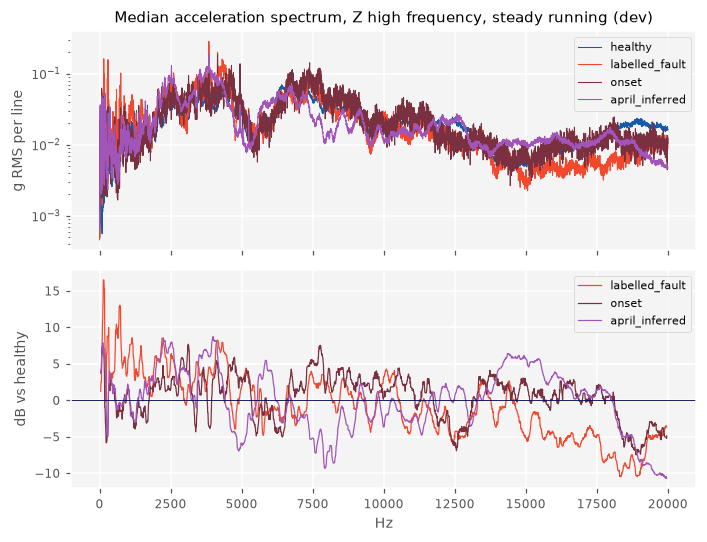

In [10]:
f_chk, _ = get_fft(preprocess_acceleration(np.asarray(steady[HF].iloc[0], float), 51200), 51200)
print(f"get_fft check: max frequency {f_chk.max():.0f} Hz (expected about 20,000)")

GROUPS = {"healthy": ["train", "val_healthy"], "labelled_fault": ["labelled_fault"],
          "onset": ["onset"], "april_inferred": ["april_inferred"]}
GCOL = {"healthy": COLORS["train"], "labelled_fault": COLORS["labelled_fault"],
        "onset": COLORS["onset"], "april_inferred": COLORS["april_inferred"]}

def median_spectrum(waves, fs, kind="acc"):
    amps, f_ref = [], None
    for a in waves:
        a = np.asarray(a, float)
        x = preprocess_acceleration(a, fs) if kind == "acc" else preprocess_velocity(a, fs)
        f, amp = get_fft(x, fs)
        f_ref = f if f_ref is None else f_ref
        amps.append(amp)
    n = min(map(len, amps))
    return f_ref[:n], np.median(np.vstack([a[:n] for a in amps]), axis=0)

spec = {g: median_spectrum(steady.loc[steady["split"].isin(s), HF], 51200) for g, s in GROUPS.items()}

fig, ax = plt.subplots(2, 1, figsize=(6.5, 5.0), sharex=True)
for g, (f, a) in spec.items():
    ax[0].semilogy(f, a, lw=0.7, label=g, c=GCOL[g])
ax[0].set_ylabel("g RMS per line"); ax[0].legend()
ax[0].set_title("Median acceleration spectrum, Z high frequency, steady running (dev)")
f_h, a_h = spec["healthy"]
for g in ["labelled_fault", "onset", "april_inferred"]:
    f, a = spec[g]
    n = min(len(a), len(a_h))
    db = 20 * np.log10(pd.Series(a[:n] / a_h[:n]).rolling(25, center=True).median())
    ax[1].plot(f[:n], db, lw=0.8, label=g, c=GCOL[g])
ax[1].axhline(0, c=NAVY, lw=0.6); ax[1].set_xlabel("Hz"); ax[1].set_ylabel("dB vs healthy"); ax[1].legend()
plt.tight_layout(); save_fig("fig_spectra"); plt.show()

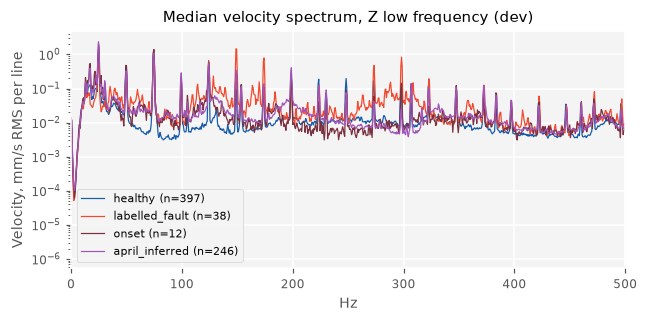

Running speed 1X: median 24.69 Hz (1481 rpm), spread 0.30 Hz


In [11]:
# Velocity spectrum, 0-500 Hz (running speed and harmonics)
has_lf = steady[LF].apply(bm._is_waveform)
fig, ax = plt.subplots(figsize=(6.5, 2.8))
for g, s in GROUPS.items():
    w = steady.loc[steady["split"].isin(s) & has_lf, LF]
    if len(w):
        f, a = median_spectrum(w, bm.FS_LF, kind="vel")
        ax.semilogy(f, a, lw=0.8, label=f"{g} (n={len(w)})", c=GCOL[g])
ax.set_xlim(0, 500); ax.set_xlabel("Hz"); ax.set_ylabel("Velocity, mm/s RMS per line")
ax.set_title("Median velocity spectrum, Z low frequency (dev)"); ax.legend()
save_fig("fig_velocity"); plt.show()

f1x = steady.loc[has_lf, LF].apply(lambda a: bm.lf_features(a)["f_1x"])
print(f"Running speed 1X: median {f1x.median():.2f} Hz ({f1x.median() * 60:.0f} rpm), spread {f1x.std():.2f} Hz")

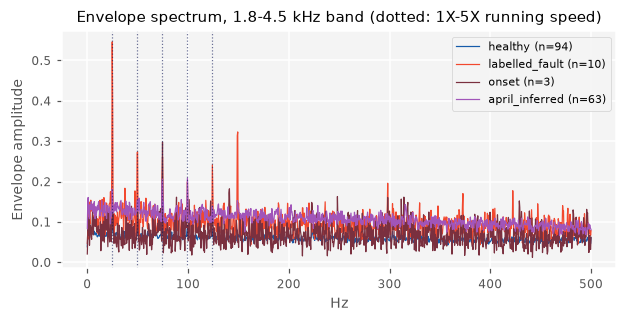

In [12]:
# Envelope spectrum in the 1.8-4.5 kHz resonance band (long-wave snapshots: 2.56 s, about 0.4 Hz resolution)
def env_spectrum(a, fs=51200, band=bm.ENV_BAND, fmax=500):
    a = np.asarray(a, float)
    x = bandpass_filter(a - a.mean(), band[0], band[1], fs)[len(a) // 10:]
    env = np.abs(hilbert(x)); env -= env.mean()
    spec_ = np.abs(np.fft.rfft(env * np.hanning(len(env)))) / len(env)
    f = np.fft.rfftfreq(len(env), 1 / fs)
    return f[f <= fmax], spec_[f <= fmax]

has_lw = steady[LW].apply(bm._is_waveform)
col_env = LW if has_lw.groupby(steady["split"]).sum().min() >= 3 else HF
fig, ax = plt.subplots(figsize=(6.5, 2.8))
for g, s in GROUPS.items():
    w = steady.loc[steady["split"].isin(s) & steady[col_env].apply(bm._is_waveform), col_env]
    if len(w):
        res = [env_spectrum(a) for a in w]
        n = min(len(r[1]) for r in res)
        ax.plot(res[0][0][:n], np.median([r[1][:n] for r in res], axis=0), lw=0.8, label=f"{g} (n={len(w)})", c=GCOL[g])
for k in range(1, 6):
    ax.axvline(k * f1x.median(), c=NAVY, ls=":", lw=0.8, alpha=0.6)
ax.set_xlabel("Hz"); ax.set_ylabel("Envelope amplitude")
ax.set_title("Envelope spectrum, 1.8-4.5 kHz band (dotted: 1X-5X running speed)")
ax.legend(); save_fig("fig_envelope"); plt.show()

### Waveform streams: which ones can the model use?

Short waves arrive about hourly; the Z long wave and audio about every 4 hours. Three checks decide whether the
4-hourly streams should be model inputs: (1) **coverage**, how often each stream arrives; (2) **redundancy**, whether
the long wave separates healthy from fault better than the short wave from the same moment; (3) **audio**, whether the
microphone follows this machine and sees the fault. Comparisons use rank correlation and Cohen's d, because envelope
features scale with recording length.

                          snapshots  per_day  median_gap_h
stream                                                    
Z short wave, high freq.       1968    16.68           1.0
Z short wave, low freq.        1965    16.65           1.0
Z long wave, high freq.         452     3.83           4.0
Audio                           450     3.81           4.0

Scored (steady) snapshots with a long wave within 30 min: 24%


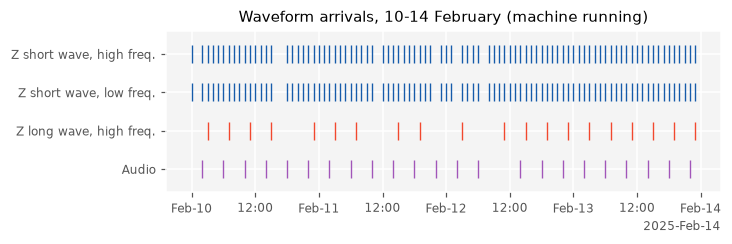

In [13]:
# Stream check 1 - coverage: how often does each waveform stream actually arrive?
AU = "Motor DE_Audio Signal"
STREAMS = {"Z short wave, high freq.": HF, "Z short wave, low freq.": LF,
           "Z long wave, high freq.": LW, "Audio": AU}
arrivals = {name: dev.loc[dev[col].apply(bm._is_waveform), "date"].sort_values() for name, col in STREAMS.items()}
n_days = (dev["date"].max() - dev["date"].min()).total_seconds() / 86400
cov = pd.DataFrame([{"stream": name, "snapshots": len(t), "per_day": len(t) / n_days,
                     "median_gap_h": t.diff().dt.total_seconds().median() / 3600}
                    for name, t in arrivals.items()]).set_index("stream")
print(cov.round(2).to_string())

# Of the snapshots the model scores, how many would have a long wave available?
lw_times = arrivals["Z long wave, high freq."].to_frame("lw_date")
near = pd.merge_asof(steady[["date"]].sort_values("date"), lw_times, left_on="date", right_on="lw_date",
                     direction="nearest", tolerance=pd.Timedelta("30min"))
print(f"\nScored (steady) snapshots with a long wave within 30 min: {near['lw_date'].notna().mean():.0%}")

# Arrival pattern during one running period
w0, w1 = pd.Timestamp("2025-02-10", tz="UTC"), pd.Timestamp("2025-02-14", tz="UTC")
fig, ax = plt.subplots(figsize=(6.5, 1.9))
for i, (name, t) in enumerate(arrivals.items()):
    tt = t[(t >= w0) & (t < w1)]
    ax.scatter(tt, np.full(len(tt), i), marker="|", s=150, c=[BLUE, BLUE, ROSE, PURPLE][i])
ax.set_yticks(range(len(arrivals))); ax.set_yticklabels(arrivals.keys()); ax.set_ylim(-0.6, len(arrivals) - 0.4)
ax.invert_yaxis(); ax.set_title("Waveform arrivals, 10-14 February (machine running)")
save_fig("fig_stream_arrivals"); plt.show()

Paired snapshots by split: {'labelled_fault': 10, 'train': 61, 'val_healthy': 33, 'onset': 3, 'april_inferred': 63}

Rank correlation between the two waves, and Cohen's d (train vs fault) from each:
                rank_corr_short_vs_long  d_Jan_short  d_Jan_long  d_Apr_short  d_Apr_long
feature                                                                                  
band_1500_4500                     0.97         6.92        8.27         3.86        3.86
env_floor                          0.94         3.76        6.59         3.20        3.64
spec_centroid                      0.99        -4.59       -4.71        -2.96       -3.03
env_1x_5x                          0.75         2.01        3.97         1.98        2.23
acc_rms                            0.97         2.17        2.14         1.34        1.31


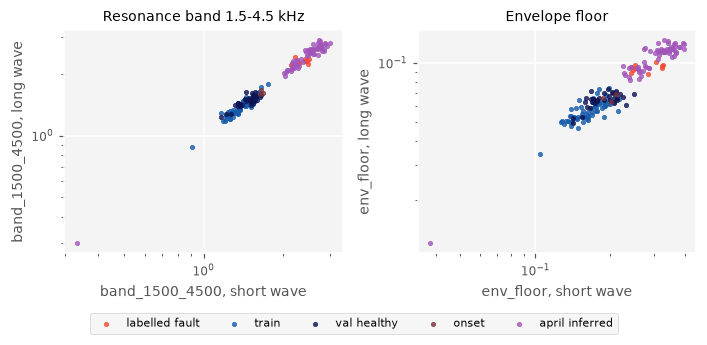

In [14]:
# Stream check 2 - redundancy: does the long wave add information beyond the hourly short wave?
# Pair each scored snapshot with the nearest long wave (within 30 min) and compute the same features on both.
from scipy.stats import spearmanr
from matplotlib.ticker import LogLocator, NullFormatter

KEY = ["band_1500_4500", "env_floor", "spec_centroid", "env_1x_5x", "acc_rms"]
lw_rows = dev.loc[dev[LW].apply(bm._is_waveform), ["date", LW]].rename(columns={"date": "lw_date"}).sort_values("lw_date")
pairs = pd.merge_asof(steady[["date", HF, "split"]].sort_values("date"), lw_rows, left_on="date",
                      right_on="lw_date", direction="nearest", tolerance=pd.Timedelta("30min")).dropna(subset=["lw_date"])
print("Paired snapshots by split:", pairs["split"].value_counts().reindex(ORDER).fillna(0).astype(int).to_dict())

f_short = pd.DataFrame([bm.hf_features(a) for a in pairs[HF]])[KEY]
f_long = pd.DataFrame([bm.hf_features(a) for a in pairs[LW]])[KEY]
sp = pairs["split"].values

def d(a, b):
    return (b.mean() - a.mean()) / np.sqrt((a.var() + b.var()) / 2)

rows = []
for k in KEY:
    r = {"feature": k, "rank_corr_short_vs_long": spearmanr(f_short[k], f_long[k])[0]}
    for lab, tgt in [("Jan", "labelled_fault"), ("Apr", "april_inferred")]:
        for src, fr in [("short", f_short), ("long", f_long)]:
            r[f"d_{lab}_{src}"] = d(fr.loc[sp == "train", k], fr.loc[sp == tgt, k])
    rows.append(r)
print("\nRank correlation between the two waves, and Cohen's d (train vs fault) from each:")
print(pd.DataFrame(rows).set_index("feature").round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(6.5, 2.9))
for ax, k in zip(axes, ["band_1500_4500", "env_floor"]):
    for s in ORDER:
        m = sp == s
        ax.scatter(f_short.loc[m, k], f_long.loc[m, k], s=8, c=COLORS[s], alpha=0.8, label=s.replace("_", " "))
    ax.set_xscale("log"); ax.set_yscale("log")
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_minor_formatter(NullFormatter())        # hide crowded minor labels
        axis.set_major_locator(LogLocator(base=10, numticks=4))
    ax.set_xlabel(f"{k}, short wave"); ax.set_ylabel(f"{k}, long wave"); ax.set_title(bm.FEATURE_LABELS[k], fontsize=9)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.08))
plt.tight_layout(); save_fig("fig_short_vs_long_wave"); plt.show()


In [15]:
# Stream check 3 - audio: does the microphone track this machine, and does it see the bearing fault?
from scipy import signal as sps

def audio_features(a, fs=11025):
    a = np.asarray(a, float); a = a - a.mean()
    f, P = sps.welch(a, fs=fs, nperseg=4096)
    band = (f >= 1500) & (f <= 4300)                     # overlaps the vibration resonance band
    return {"audio_rms": float(np.sqrt(np.mean(a ** 2))),
            "audio_band": float(np.sqrt(P[band].sum() * (f[1] - f[0])))}

au = dev.loc[dev[AU].apply(bm._is_waveform), ["date", AU]].sort_values("date")
au = pd.merge_asof(au, snap[["date", "wf_rms", "running", "steady"]].sort_values("date"), on="date",
                   direction="nearest", tolerance=pd.Timedelta("30min")).dropna(subset=["running"])
au = pd.concat([au.reset_index(drop=True), pd.DataFrame([audio_features(a) for a in au[AU]])], axis=1)
au["running"] = au["running"].astype(bool)

# (a) Machine on vs off: vibration changes by orders of magnitude; does audio?
on, off = au[au["running"]], au[~au["running"]]
print(f"Audio snapshots matched to a vibration snapshot: {len(au)} (running {len(on)}, stopped {len(off)})")
print(f"Median vibration RMS, running / stopped: {on['wf_rms'].median() / off['wf_rms'].median():8.1f} x")
print(f"Median audio RMS,     running / stopped: {on['audio_rms'].median() / off['audio_rms'].median():8.2f} x")
print(f"Rank correlation, audio RMS vs vibration RMS (running only): {spearmanr(on['audio_rms'], on['wf_rms'])[0]:.2f}")

# (b) Healthy vs fault, steady running only
st_au = au[au["steady"].astype(bool)].copy()
st_au["split"] = st_au["date"].apply(split_of)
print("\nSteady audio snapshots by split:", st_au["split"].value_counts().reindex(ORDER).fillna(0).astype(int).to_dict())
for k in ["audio_rms", "audio_band"]:
    tr_ = st_au.loc[st_au["split"] == "train", k]
    print(f"Cohen's d {k:10s}  Jan: {d(tr_, st_au.loc[st_au['split'] == 'labelled_fault', k]):6.2f}"
          f"   Apr: {d(tr_, st_au.loc[st_au['split'] == 'april_inferred', k]):6.2f}")


Audio snapshots matched to a vibration snapshot: 442 (running 183, stopped 259)
Median vibration RMS, running / stopped:    293.3 x
Median audio RMS,     running / stopped:   155.16 x
Rank correlation, audio RMS vs vibration RMS (running only): 0.36

Steady audio snapshots by split: {'labelled_fault': 9, 'train': 63, 'val_healthy': 33, 'onset': 3, 'april_inferred': 62}
Cohen's d audio_rms   Jan:   1.89   Apr:   2.29
Cohen's d audio_band  Jan:   0.29   Apr:   0.46


**Reading.** Short waves arrive about hourly; the long wave and audio about every 4 hours, so only 24% of scored
snapshots (170 of 699) have a long wave within 30 minutes. On paired snapshots the long wave agrees closely with the short
wave (rank correlation 0.94 to 0.99, except 0.75 for 1X-5X modulation) and separates April equally well (band-energy
d 3.86 for both); it sharpens the envelope features, mainly on the 10 January pairs. The microphone follows this machine
(about 155 times louder when running), and overall audio level rises in both faults (d 1.9 and 2.3), but the band that
overlaps the bearing resonance barely changes (d 0.3 and 0.5): audio reflects overall loudness, not the bearing signature.

**The model therefore uses the hourly short waves only**; the long wave is kept for envelope diagnostics and audio is
future work.

## 7. Feature engineering

21 features per steady snapshot (`bearing_model.build_features`), extending the provided utilities: time-domain statistics,
seven band energies, spectral centroid, envelope features in the resonance band, and velocity features. The same function is
used at inference, so training and production features cannot drift apart. This cell takes a few minutes.

In [16]:
feats = bm.build_features(steady)
F = pd.concat([steady[["date", "run_id", "wf_rms", "split"]], feats], axis=1)
FEATS_ALL = list(feats.columns)
print(F.shape); print(F["split"].value_counts().reindex(ORDER))
F.head()

(699, 25)
split
labelled_fault     38
train             269
val_healthy       129
onset              13
april_inferred    250
Name: count, dtype: int64


,date,run_id,wf_rms,split,vel_rms,f_1x,vel_1x,vel_2x,vel_305,vel_floor,...,band_500_1500,band_1500_4500,band_4500_9000,band_9000_13000,band_13000_17000,band_17000_20000,ratio_low_high,env_kurt,env_floor,env_1x_5x
18,2025-01-02 10:00:00+00:00,0.0,28.456700,labelled_fault,4.119979,24.689572,0.556759,0.513550,0.214562,0.020060,...,0.448642,2.100015,1.681356,0.568065,0.230648,0.241703,0.885869,0.530728,0.274129,2.228101
19,2025-01-02 11:00:00+00:00,0.0,31.082252,labelled_fault,4.108563,24.689572,0.560993,0.599911,0.155575,0.016933,...,0.416699,2.488155,1.815076,0.624856,0.241320,0.248100,0.853726,0.447366,0.282398,2.943150
20,2025-01-02 12:00:00+00:00,0.0,30.131642,labelled_fault,3.936128,24.689572,0.634847,0.577030,0.109196,0.014412,...,0.463842,2.279017,1.891411,0.645914,0.270805,0.261849,0.754959,0.138086,0.280873,1.878398
21,2025-01-02 13:00:00+00:00,0.0,29.641882,labelled_fault,3.862781,24.689572,0.544533,0.528140,0.155815,0.017428,...,0.483126,2.300447,1.697168,0.635268,0.251533,0.260551,0.799659,0.309476,0.263355,3.001687
22,2025-01-02 14:00:00+00:00,0.0,30.707418,labelled_fault,3.898936,24.689572,0.674381,0.376846,0.088324,0.015108,...,0.493594,2.330708,1.823403,0.681601,0.266215,0.272477,0.794302,-0.016588,0.249715,1.659429


### Exploratory projections (not used by the model)

Linear PCA, Kernel PCA and t-SNE are fitted on all steady development snapshots **without labels**; the splits only colour
the points afterwards. They check whether healthy and fault snapshots separate before any model is trained.

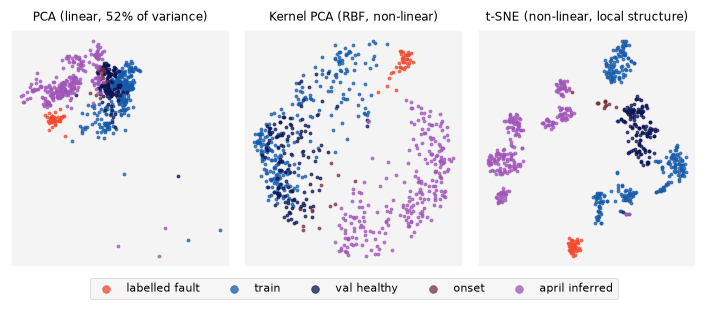

PC1 (32%) top loadings: {'spec_centroid': 0.35, 'band_1500_4500': -0.35, 'env_floor': -0.34, 'vel_floor': -0.33, 'env_1x_5x': -0.33}
PC2 (20%) top loadings: {'band_13000_17000': 0.38, 'band_17000_20000': 0.35, 'ratio_low_high': -0.34, 'acc_rms': 0.33, 'band_4500_9000': 0.33}

Silhouette, healthy vs fault:
  PCA         0.45
  Kernel PCA  0.50
  t-SNE       0.47


In [17]:
# Exploratory views of the 21 features: is there structure before any labels are used?
# All three are fitted on every steady development snapshot WITHOUT labels;
# the split names below only colour the points afterwards. Held-out data is not included.
from sklearn.decomposition import PCA, KernelPCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

Xe = np.log(F[FEATS_ALL].abs() + 1e-9).dropna()      # log: features span orders of magnitude
Se = F.loc[Xe.index, "split"]
Ze = np.clip(StandardScaler().fit_transform(Xe), -6, 6)   # cap a few transient outliers

pca_e = PCA(n_components=2).fit(Ze)
emb = {
    f"PCA (linear, {pca_e.explained_variance_ratio_.sum():.0%} of variance)": pca_e.transform(Ze),
    "Kernel PCA (RBF, non-linear)": KernelPCA(n_components=2, kernel="rbf", gamma=1 / len(FEATS_ALL),
                                              random_state=0).fit_transform(Ze),
    "t-SNE (non-linear, local structure)": TSNE(n_components=2, perplexity=30, init="pca",
                                                learning_rate="auto", random_state=0).fit_transform(Ze),
}

fig, axes = plt.subplots(1, 3, figsize=(6.5, 2.6))
for ax, (title, Z) in zip(axes, emb.items()):
    for sp in ORDER:
        m = (Se == sp).values
        ax.scatter(Z[m, 0], Z[m, 1], s=4, c=COLORS[sp], alpha=0.75, label=sp.replace("_", " "))
    ax.set_title(title, fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])                  # projected axes have no physical units
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.08), markerscale=2.5)
plt.tight_layout(); save_fig("fig_embeddings"); plt.show()

# What the linear axes mean
for k in (0, 1):
    top = pd.Series(pca_e.components_[k], index=Xe.columns).sort_values(key=abs, ascending=False).head(5)
    print(f"PC{k + 1} ({pca_e.explained_variance_ratio_[k]:.0%}) top loadings:", top.round(2).to_dict())

# How cleanly does each view separate healthy from fault snapshots? (1 = fully separate, 0 = mixed)
grp = np.select([Se.isin(["train", "val_healthy"]), Se.isin(["labelled_fault", "april_inferred"])],
                ["healthy", "fault"], "other")
keep = grp != "other"
print("\nSilhouette, healthy vs fault:")
for title, Z in emb.items():
    print(f"  {title.split(' (')[0]:11s} {silhouette_score(Z[keep], grp[keep]):.2f}")

## 8. Feature selection

Effect size (Cohen's d) between healthy training data and (a) the **labelled January fault** and (b) April (inferred).
Features are kept when they separate strongly **in both episodes with the same sign** and have a physical bearing-fault
interpretation. Held-out data is not used.

In [18]:
def cohen_d(a, b):
    return (b.mean() - a.mean()) / np.sqrt((a.var() + b.var()) / 2)

H = F[F["split"] == "train"]
sep = pd.DataFrame({
    "d_labelled_jan": [cohen_d(H[c], F.loc[F["split"] == "labelled_fault", c]) for c in FEATS_ALL],
    "d_april_inferred": [cohen_d(H[c], F.loc[F["split"] == "april_inferred", c]) for c in FEATS_ALL],
}, index=FEATS_ALL).round(2)
sep["same_sign"] = np.sign(sep["d_labelled_jan"]) == np.sign(sep["d_april_inferred"])
sep["in_BHI"] = sep.index.isin(list(bm.BHI_FEATS))
print(sep.sort_values("d_labelled_jan", key=abs, ascending=False).to_string())

                  d_labelled_jan  d_april_inferred  same_sign  in_BHI
band_1500_4500              6.24              4.04       True    True
band_500_1500               5.37             -0.58      False   False
ratio_low_high              4.74              0.41       True   False
vel_rms                     4.35              1.52       True   False
spec_centroid              -4.34             -2.77       True    True
band_10_500                 4.21              0.38       True   False
vel_floor                   4.03              1.60       True   False
env_floor                   4.01              3.44       True    True
env_1x_5x                   2.39              2.20       True    True
band_17000_20000           -2.28             -1.11       True   False
band_13000_17000           -2.02              1.15      False   False
acc_rms                     1.84              1.47       True   False
vel_305                     1.77              1.22       True   False
vel_1x              

**Selection.** The Bearing Health Index (BHI) uses four bearing-specific features: resonance-band energy (1.5-4.5 kHz),
envelope floor, spectral centroid (falls as energy shifts lower) and envelope 1X-5X modulation. Velocity and low-band
features feed the general anomaly score but are kept out of the BHI, because they also respond to load and operating
regime. Bands above 13 kHz are excluded: energy at the highest frequencies is known to fade as bearing damage advances, and
the top band lies in the anti-aliasing roll-off.

## 9. Bearing Health Index and anomaly model

- **BHI**: mean of four signed z-scores against the healthy baseline (median-centred), smoothed with a 6-snapshot rolling
  median within each run.
- **Warning** = 99.5th percentile of the smoothed BHI on healthy data (train + val_healthy): *outside the healthy range*.
- **Alarm** = level exceeded by 90% of the labelled January fault: *as severe as a confirmed fault*.
- **General anomaly score**: robust Mahalanobis distance (minimum covariance determinant) on eight features.

In [19]:
art = bm.fit_artifacts(F, split_col="split", train="train", healthy_val="val_healthy", fault="labelled_fault")
bm.save_artifacts(art, "model_artifacts.joblib")
print({k: round(v, 2) for k, v in art.items() if isinstance(v, float)})

contrib = bm.bhi_contributions(F, art)
F["bhi_raw"] = contrib.sum(axis=1)
F["bhi"] = bm._smooth(F["bhi_raw"], F["run_id"])
F["mahal"] = bm._smooth(bm.mahalanobis(F, art), F["run_id"])

def status_table(score, split, warn, alarm, order=ORDER):
    s = pd.DataFrame({"score": score, "split": split}).dropna()
    s["status"] = np.select([s["score"] >= alarm, s["score"] >= warn], ["alarm", "warning"], "normal")
    t = pd.crosstab(s["split"], s["status"], normalize="index").reindex(
        index=order, columns=["normal", "warning", "alarm"], fill_value=0)
    t.insert(0, "n", s.groupby("split").size().reindex(order))
    t["median_score"] = s.groupby("split")["score"].median().reindex(order)
    return t.round(3)

print("\nBearing Health Index by split (assessed snapshots):")
print(status_table(F["bhi"], F["split"], art["bhi_warn"], art["bhi_alarm"]))

{'bhi_warn': 1.5, 'bhi_alarm': 2.81, 'anomaly_thr': 31.76}

Bearing Health Index by split (assessed snapshots):
status            n  normal  warning  alarm  median_score
split                                                    
labelled_fault   36   0.000    0.111  0.889         2.915
train           254   0.992    0.008  0.000         0.118
val_healthy     123   1.000    0.000  0.000         0.492
onset            11   1.000    0.000  0.000         1.017
april_inferred  240   0.000    0.350  0.650         3.586


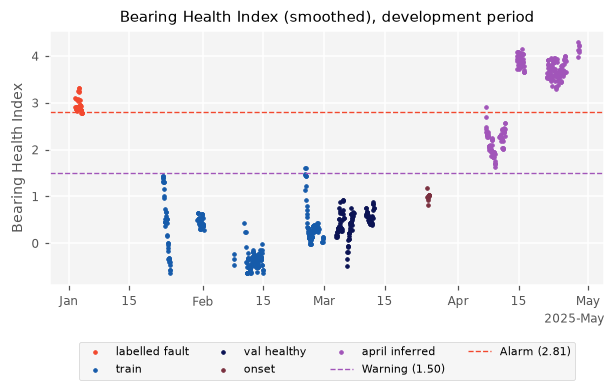

In [20]:
fig, ax = plt.subplots(figsize=(6.5, 3.0))
for sp in ORDER:
    g = F[F["split"] == sp]
    ax.scatter(g["date"], g["bhi"], s=6, c=COLORS[sp], label=sp.replace("_", " "))
ax.axhline(art["bhi_warn"], c=WARN_C, ls="--", label=f"Warning ({art['bhi_warn']:.2f})")
ax.axhline(art["bhi_alarm"], c=ALARM_C, ls="--", label=f"Alarm ({art['bhi_alarm']:.2f})")
ax.set_ylabel("Bearing Health Index"); ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.set_title("Bearing Health Index (smoothed), development period")
save_fig("fig_bhi_dev"); plt.show()

## 10. Model comparison: anomaly detection vs supervised

All models are judged on data they were not fitted on: **val_healthy** (false alarms), **onset**, and **april_inferred**
(a second fault episode, never used for fitting or thresholds). Supervised models are trained on `train` (healthy) vs the
labelled January fault, so their score on `labelled_fault` is in-sample.

In [21]:
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score

D = F.dropna(subset=FEATS_ALL).copy()
X = np.log(D[FEATS_ALL].abs() + 1e-9)
healthy_m = D["split"].isin(["train", "val_healthy"])
smooth = lambda s: bm._smooth(pd.Series(s, index=D.index), D["run_id"])

# Isolation Forest (healthy only)
iso = IsolationForest(n_estimators=300, random_state=0).fit(X[D["split"] == "train"])
D["iso"] = smooth(-iso.score_samples(X))

# Supervised: healthy (train) vs labelled January fault
fit_m = D["split"].isin(["train", "labelled_fault"])
y = (D["split"] == "labelled_fault").astype(int)
models = {
    "random_forest": RandomForestClassifier(n_estimators=500, max_depth=4, min_samples_leaf=5,
                                            class_weight="balanced", random_state=0),
    "logistic_reg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5)),
}
for name, m in models.items():
    m.fit(X[fit_m], y[fit_m])
    D[name] = smooth(m.predict_proba(X)[:, 1])

scores = {  # name: (column, threshold, fitted on healthy only?)
    "BHI (Warning)": ("bhi", art["bhi_warn"], True),
    "BHI (Alarm)": ("bhi", art["bhi_alarm"], True),
    "Mahalanobis": ("mahal", art["anomaly_thr"], True),
    "Isolation Forest": ("iso", np.nanquantile(D.loc[healthy_m, "iso"], 0.995), True),
    "Random forest": ("random_forest", 0.5, False),
    "Logistic regression": ("logistic_reg", 0.5, False),
}
ev = D["split"].isin(["val_healthy", "april_inferred"])
rows = []
for name, (col, thr, healthy_only) in scores.items():
    s = D[[col, "split"]].dropna()
    rate = lambda sp: (s.loc[s["split"] == sp, col] >= thr).mean()
    e = s[s["split"].isin(["val_healthy", "april_inferred"])]
    rows.append({"model": name, "trained_on": "healthy only" if healthy_only else "healthy + Jan fault",
                 "false_alarms_val_healthy": rate("val_healthy"), "onset": rate("onset"),
                 "april_inferred": rate("april_inferred"), "labelled_jan": rate("labelled_fault"),
                 "AP_march_vs_april": average_precision_score(e["split"] == "april_inferred", e[col])})
comparison = pd.DataFrame(rows).set_index("model").round(3)
print(comparison.to_string())

                              trained_on  false_alarms_val_healthy  onset  april_inferred  labelled_jan  AP_march_vs_april
model                                                                                                                     
BHI (Warning)               healthy only                       0.0    0.0           1.000         1.000               1.00
BHI (Alarm)                 healthy only                       0.0    0.0           0.657         0.889               1.00
Mahalanobis                 healthy only                       0.0    0.0           0.000         0.333               1.00
Isolation Forest            healthy only                       0.0    0.0           0.775         1.000               1.00
Random forest        healthy + Jan fault                       0.0    0.0           0.475         1.000               1.00
Logistic regression  healthy + Jan fault                       0.0    0.0           0.746         1.000               0.99


In [22]:
# k-NN distance health index (after Tian et al., 2016): PCA on the features, then the mean
# distance from each snapshot to its K nearest HEALTHY training snapshots. Healthy data only.
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score

K = 5
Xv = X.values                                     # log features from the comparison cell
tr = (D["split"] == "train").values
knn_proj = make_pipeline(StandardScaler(), PCA(n_components=0.95, random_state=0)).fit(Xv[tr])
nn = NearestNeighbors(n_neighbors=K + 1).fit(knn_proj.transform(Xv[tr]))

def knn_score(Xq, exclude_self=False):
    d, _ = nn.kneighbors(knn_proj.transform(Xq))
    return (d[:, 1:] if exclude_self else d[:, :K]).mean(axis=1)

raw = knn_score(Xv)
raw[tr] = knn_score(Xv[tr], exclude_self=True)   # a training point must not count itself
D["knn"] = smooth(raw)
knn_thr = np.nanquantile(D.loc[healthy_m, "knn"], 0.995)   # same rule as the BHI Warning

s = D[["knn", "split"]].dropna()
rate = lambda sp: (s.loc[s["split"] == sp, "knn"] >= knn_thr).mean()
e = s[s["split"].isin(["val_healthy", "april_inferred"])]
comparison.loc["kNN distance (Tian et al.)"] = pd.Series({
    "trained_on": "healthy only",
    "false_alarms_val_healthy": rate("val_healthy"),
    "onset": rate("onset"),
    "april_inferred": rate("april_inferred"),
    "labelled_jan": rate("labelled_fault"),
    "AP_march_vs_april": average_precision_score(e["split"] == "april_inferred", e["knn"]),
})
print(f"PCA kept {knn_proj[-1].n_components_} components (95% of variance); threshold {knn_thr:.2f}\n")
print(comparison.round(3).to_string())

PCA kept 11 components (95% of variance); threshold 4.53

                                     trained_on  false_alarms_val_healthy  onset  april_inferred  labelled_jan  AP_march_vs_april
model                                                                                                                            
BHI (Warning)                      healthy only                     0.000    0.0           1.000         1.000              1.000
BHI (Alarm)                        healthy only                     0.000    0.0           0.657         0.889              1.000
Mahalanobis                        healthy only                     0.000    0.0           0.000         0.333              1.000
Isolation Forest                   healthy only                     0.000    0.0           0.775         1.000              1.000
Random forest               healthy + Jan fault                     0.000    0.0           0.475         1.000              1.000
Logistic regression         heal

**Reading.** Average precision near 1 means a model ranks April snapshots above healthy ones almost perfectly; differences in
detection rates then come from threshold calibration. Note that the healthy-only models never saw the January fault, so their
detection of it is independent evidence, while the supervised models were trained on it.

The k-NN distance health index (after Tian et al., 2016) uses all 21 features through PCA. It ranks April almost as well as
the BHI but, at the same 99.5th-percentile rule, gives a few false warnings and misses part of April: load-related features
widen its healthy range. The BHI, restricted to four bearing-specific features, is kept as the primary model.

## 11. Feature importance (supervised models)

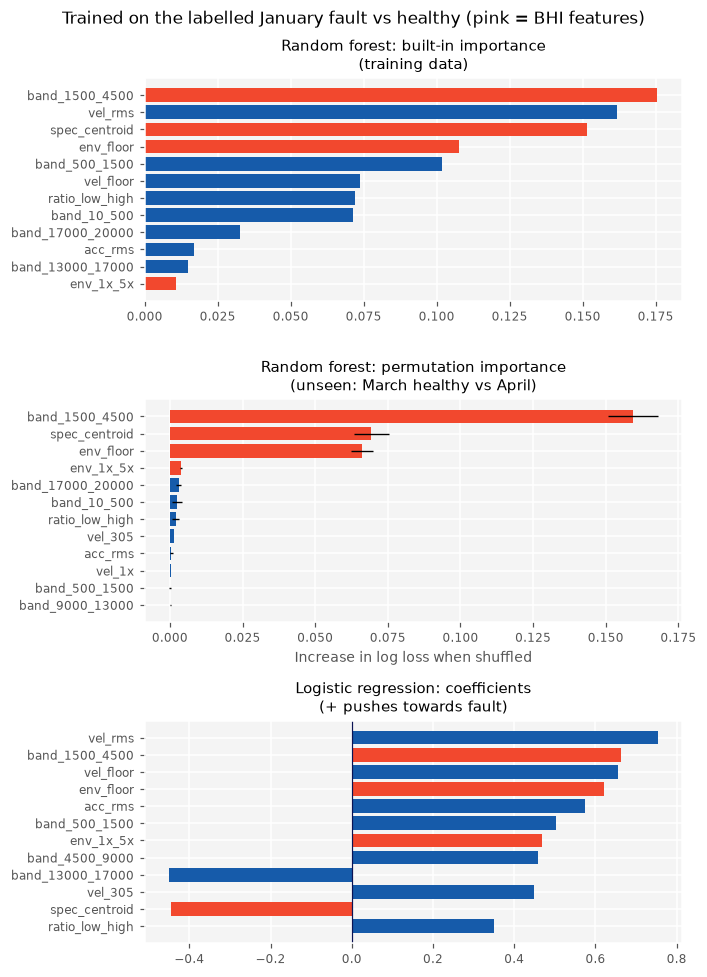

In [23]:
from sklearn.inspection import permutation_importance

rf, lr = models["random_forest"], models["logistic_reg"]
ev = D["split"].isin(["val_healthy", "april_inferred"])
y_ev = (D.loc[ev, "split"] == "april_inferred").astype(int)
pi = permutation_importance(rf, X[ev], y_ev, n_repeats=30, random_state=0, scoring="neg_log_loss")

imp_rf = pd.Series(rf.feature_importances_, index=FEATS_ALL)
imp_perm = pd.Series(pi.importances_mean, index=FEATS_ALL)
imp_sd = pd.Series(pi.importances_std, index=FEATS_ALL)
coef = pd.Series(lr.named_steps["logisticregression"].coef_[0], index=FEATS_ALL)

col = lambda idx: [ROSE if f in bm.BHI_FEATS else BLUE for f in idx]
fig, axes = plt.subplots(3, 1, figsize=(6.5, 9.0))
s = imp_rf.sort_values().tail(12)
axes[0].barh(s.index, s.values, color=col(s.index)); axes[0].set_title("Random forest: built-in importance\n(training data)")
s = imp_perm.sort_values().tail(12)
axes[1].barh(s.index, s.values, xerr=imp_sd[s.index], color=col(s.index))
axes[1].set_title("Random forest: permutation importance\n(unseen: March healthy vs April)")
axes[1].set_xlabel("Increase in log loss when shuffled")
s = coef.reindex(coef.abs().sort_values().tail(12).index)
axes[2].barh(s.index, s.values, color=col(s.index)); axes[2].axvline(0, c=NAVY, lw=0.8)
axes[2].set_title("Logistic regression: coefficients\n(+ pushes towards fault)")
for a in axes: a.tick_params(axis="y", labelsize=8)
fig.suptitle("Trained on the labelled January fault vs healthy (pink = BHI features)")
plt.tight_layout(); save_fig("fig_feature_importance"); plt.show()

## 12. Explainability

The BHI is a sum of four feature contributions, so every score breaks down exactly into physical mechanisms. The
Mahalanobis score splits into per-feature terms that sum exactly to the squared distance.

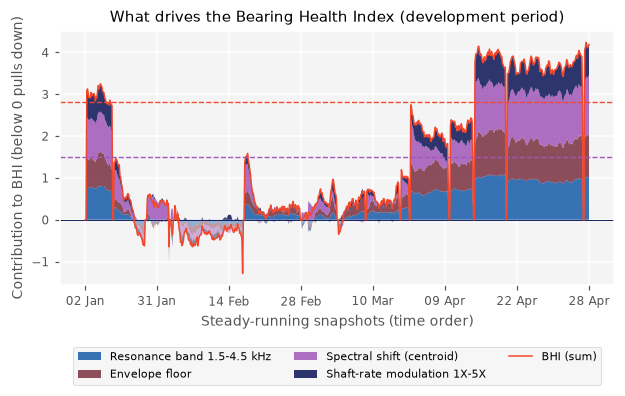

In [24]:
LABELS = [bm.FEATURE_LABELS[f] for f in bm.BHI_FEATS]

def plot_contributions(Fx, contrib_x, title, name):
    sm = contrib_x.groupby(Fx["run_id"]).transform(lambda s: s.rolling(bm.WINDOW, min_periods=bm.MIN_PERIODS).mean())
    sm.columns = LABELS
    x = np.arange(len(Fx))
    fig, ax = plt.subplots(figsize=(6.5, 3.0))
    cols = [BLUE, PINK, PURPLE, NAVY][:len(LABELS)]
    ax.stackplot(x, sm.clip(lower=0).fillna(0).T.values, labels=LABELS, colors=cols, alpha=0.85)
    ax.stackplot(x, sm.clip(upper=0).fillna(0).T.values, colors=cols, alpha=0.45)  # negative terms below zero
    ax.axhline(0, c=NAVY, lw=0.6)
    ax.plot(x, sm.sum(axis=1), c=ROSE, lw=1.0, label="BHI (sum)")
    ax.axhline(art["bhi_warn"], c=WARN_C, ls="--"); ax.axhline(art["bhi_alarm"], c=ALARM_C, ls="--")
    ticks = np.linspace(0, len(Fx) - 1, 8).astype(int)
    ax.set_xticks(ticks); ax.set_xticklabels(Fx["date"].iloc[ticks].dt.strftime("%d %b"))
    ax.set_xlabel("Steady-running snapshots (time order)"); ax.set_ylabel("Contribution to BHI (below 0 pulls down)")
    ax.set_title(title); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3)
    save_fig(name); plt.show()

plot_contributions(F, contrib, "What drives the Bearing Health Index (development period)", "fig_bhi_contributions_dev")

In [25]:
# Plain-language explanation for the highest-scoring April snapshot
i = F.loc[F["split"] == "april_inferred", "bhi"].idxmax()
row = pd.Series({"date": F.at[i, "date"], "bhi": F.at[i, "bhi"],
                 "status": "alarm" if F.at[i, "bhi"] >= art["bhi_alarm"] else "warning",
                 **{f"c_{f}": contrib.at[i, f] for f in bm.BHI_FEATS}})
print(bm.explain_alert(row))

# Which features drive the general anomaly score, by split (median per-feature terms)
MC = bm.mahalanobis_contributions(F, art)
print("\nMedian Mahalanobis contribution by split:")
print(MC.groupby(F.loc[MC.index, "split"]).median().reindex(ORDER).round(1).to_string())

28 Apr 2025 19:00  status=alarm  BHI=4.29
  - Spectral shift (centroid): +1.46 (5.8 sd above baseline): energy has shifted towards lower frequencies (damage spreading)
  - Envelope floor: +1.15 (4.6 sd above baseline): vibration in the resonance band has become more impulsive (repeated impacts)
  - Resonance band 1.5-4.5 kHz: +1.14 (4.6 sd above baseline): impacts are exciting the 2-4 kHz structural resonances (typical of bearing defects)
  - Shaft-rate modulation 1X-5X: +0.94 (3.7 sd above baseline): impacts are modulated at shaft speed (consistent with an inner-race defect or looseness)

Median Mahalanobis contribution by split:
                band_1500_4500  env_floor  spec_centroid  env_1x_5x  acc_rms  vel_1x  vel_305  vel_rms
split                                                                                                 
labelled_fault             4.2      -28.5          184.1       12.2      5.2   354.6     74.2    264.7
train                      0.3        0.2           

## 13. Robustness check

Each BHI feature is removed in turn, the Warning threshold recomputed on healthy data, and detection re-measured. If one
feature carried the whole index, removing it would collapse detection.

In [26]:
# Leave-one-feature-out: does the BHI depend on any single feature?
z = bm.bhi_zscores(F, art)
rows = []
for drop in [None] + list(bm.BHI_FEATS):
    cols = [c for c in bm.BHI_FEATS if c != drop]
    b = bm._smooth(z[cols].mean(axis=1), F["run_id"])
    warn = np.nanquantile(b[F["split"].isin(["train", "val_healthy"])], 0.995)
    r = {"dropped": drop or "(none)", "warning_thr": round(warn, 2)}
    for sp in ["val_healthy", "labelled_fault", "april_inferred"]:
        r[sp] = round((b[F["split"] == sp].dropna() >= warn).mean(), 3)
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))

       dropped  warning_thr  val_healthy  labelled_fault  april_inferred
        (none)         1.50          0.0             1.0           1.000
band_1500_4500         1.51          0.0             1.0           0.979
     env_floor         1.68          0.0             1.0           0.971
 spec_centroid         1.17          0.0             1.0           1.000
     env_1x_5x         1.63          0.0             1.0           1.000


## 14. Final evaluation on the held-out period (29 April to 9 June 2025)

The model and thresholds are now frozen (`model_artifacts.joblib`). The held-out rows are scored **once**, exactly as a new
period would be in production: raw rows in, status and explanation out. The brief labels this whole period as a bearing fault.

Notes:
- Only steady-running snapshots can be assessed; the rest are `stopped` or `not_assessed`.
- Scoring starts fresh at 29 April, so `condition` is `unknown` until the first assessed snapshot.

In [27]:
art = bm.load_artifacts("model_artifacts.joblib")
pred_h = bm.predict(holdout, art)

assessed = pred_h[pred_h["status"].isin(["normal", "warning", "alarm"])]
print(f"Held-out waveform snapshots: {len(pred_h)} | assessed (steady running, smoothed): {len(assessed)}")
print("\nStatus, all snapshots:"); print(pred_h["status"].value_counts().to_string())
print("\nStatus, assessed snapshots:"); print(assessed["status"].value_counts(normalize=True).round(3).to_string())
print("\nCondition (last assessed status carried through stops):")
print(pred_h["condition"].value_counts(normalize=True).round(3).to_string())
print(f"\nMedian BHI on held-out: {assessed['bhi'].median():.2f} (Warning {art['bhi_warn']:.2f}, Alarm {art['bhi_alarm']:.2f})")

Held-out waveform snapshots: 711 | assessed (steady running, smoothed): 317

Status, all snapshots:
status
stopped         364
alarm           317
not_assessed     30

Status, assessed snapshots:
status
alarm    1.0

Condition (last assessed status carried through stops):
condition
alarm      0.993
unknown    0.007

Median BHI on held-out: 3.89 (Warning 1.50, Alarm 2.81)


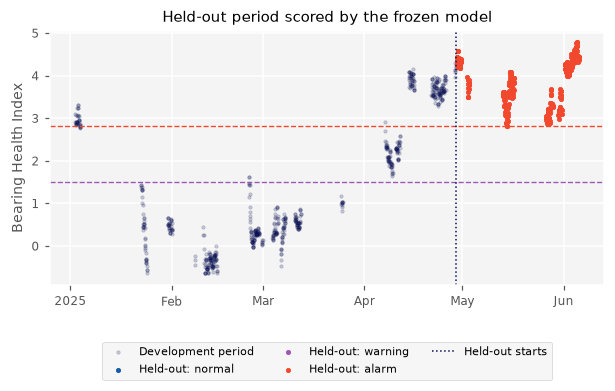

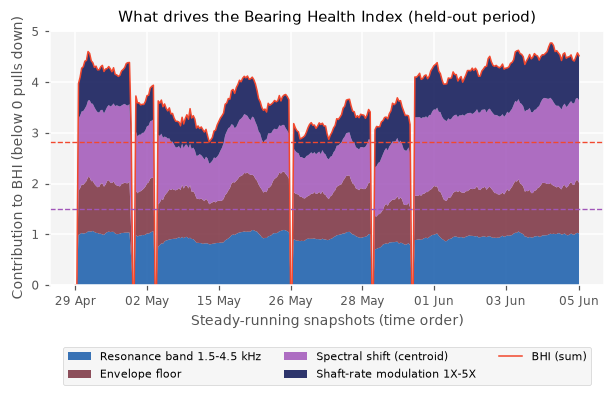

In [28]:
fig, ax = plt.subplots(figsize=(6.5, 3.0))
dev_p = F.dropna(subset=["bhi"])
ax.scatter(dev_p["date"], dev_p["bhi"], s=5, c=NAVY, alpha=0.2, label="Development period")
for st, c in STATUS_C.items():
    g = pred_h[pred_h["status"] == st]
    ax.scatter(g["date"], g["bhi"], s=8, c=c, label=f"Held-out: {st}")
ax.axhline(art["bhi_warn"], c=WARN_C, ls="--"); ax.axhline(art["bhi_alarm"], c=ALARM_C, ls="--")
ax.axvline(HOLDOUT_START, c=NAVY, ls=":", lw=1, label="Held-out starts")
ax.set_ylabel("Bearing Health Index"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.set_title("Held-out period scored by the frozen model")
save_fig("fig_bhi_heldout"); plt.show()

ph = pred_h[pred_h["bhi"].notna()].reset_index(drop=True)
contrib_h = ph[[f"c_{f}" for f in bm.BHI_FEATS]].copy(); contrib_h.columns = list(bm.BHI_FEATS)
plot_contributions(ph, contrib_h, "What drives the Bearing Health Index (held-out period)", "fig_bhi_contributions_heldout")

In [29]:
# Explanations for held-out alerts
alerts = pred_h[pred_h["status"].isin(["warning", "alarm"])]
print("Top driver of held-out warnings and alarms:")
print(alerts["top_driver"].value_counts().to_string())
for name, idx in [("First alert", alerts.index.min()), ("Highest BHI", pred_h["bhi"].idxmax())]:
    if pd.notna(idx):
        print(f"\n{name}:"); print(bm.explain_alert(pred_h.loc[idx]))

Top driver of held-out warnings and alarms:
top_driver
Spectral shift (centroid)      215
Envelope floor                  71
Resonance band 1.5-4.5 kHz      30
Shaft-rate modulation 1X-5X      1

First alert:
29 Apr 2025 05:00  status=alarm  BHI=4.29
  - Spectral shift (centroid): +1.44 (5.8 sd above baseline): energy has shifted towards lower frequencies (damage spreading)
  - Resonance band 1.5-4.5 kHz: +1.11 (4.5 sd above baseline): impacts are exciting the 2-4 kHz structural resonances (typical of bearing defects)
  - Envelope floor: +1.07 (4.3 sd above baseline): vibration in the resonance band has become more impulsive (repeated impacts)
  - Shaft-rate modulation 1X-5X: +0.65 (2.6 sd above baseline): impacts are modulated at shaft speed (consistent with an inner-race defect or looseness)

Highest BHI:
05 Jun 2025 00:00  status=alarm  BHI=4.78
  - Spectral shift (centroid): +1.66 (6.6 sd above baseline): energy has shifted towards lower frequencies (damage spreading)
  - Shaft-rat

In [30]:
# The comparison models on the held-out period (same frozen models and thresholds)
snap_h = bm.steady_snapshots(holdout)
st_h = snap_h[snap_h["steady"]]
F_h = pd.concat([st_h[["date", "run_id"]], bm.build_features(st_h)], axis=1).dropna(subset=FEATS_ALL)
X_h = np.log(F_h[FEATS_ALL].abs() + 1e-9)
sm_h = lambda s: bm._smooth(pd.Series(s, index=F_h.index), F_h["run_id"])
held = {
    "BHI (Warning)": (sm_h(bm.bhi_contributions(F_h, art).sum(axis=1)), art["bhi_warn"]),
    "BHI (Alarm)": (sm_h(bm.bhi_contributions(F_h, art).sum(axis=1)), art["bhi_alarm"]),
    "Mahalanobis": (sm_h(bm.mahalanobis(F_h, art)), art["anomaly_thr"]),
    "Isolation Forest": (sm_h(-iso.score_samples(X_h)), scores["Isolation Forest"][1]),
    "Random forest": (sm_h(models["random_forest"].predict_proba(X_h)[:, 1]), 0.5),
    "Logistic regression": (sm_h(models["logistic_reg"].predict_proba(X_h)[:, 1]), 0.5),
    "kNN distance (Tian et al.)": (sm_h(knn_score(X_h.values)), knn_thr),
}
comparison["heldout"] = pd.Series({k: (v.dropna() >= thr).mean() for k, (v, thr) in held.items()}).round(3)
print(comparison[["trained_on", "false_alarms_val_healthy", "april_inferred", "heldout"]].to_string())

                                     trained_on  false_alarms_val_healthy  april_inferred  heldout
model                                                                                             
BHI (Warning)                      healthy only                   0.00000        1.000000    1.000
BHI (Alarm)                        healthy only                   0.00000        0.657000    1.000
Mahalanobis                        healthy only                   0.00000        0.000000    0.421
Isolation Forest                   healthy only                   0.00000        0.775000    1.000
Random forest               healthy + Jan fault                   0.00000        0.475000    1.000
Logistic regression         healthy + Jan fault                   0.00000        0.746000    1.000
kNN distance (Tian et al.)         healthy only                   0.01626        0.813559    1.000


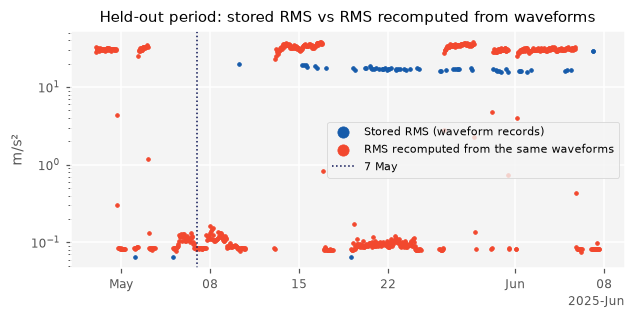

Waveform RMS / stored RMS in the same record, running snapshots:
  before 7 May  n=   3  median ratio 1.06
  from 7 May    n=  28  median ratio 1.90
The model recomputes RMS from waveforms, so its predictions are not affected.


In [31]:
# Data quality, discovered only when scoring the held-out period:
# the stored RMS inside waveform records stops tracking the machine from 7 May.
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.scatter(snap_h["date"], snap_h[RMS_COL], s=6, label="Stored RMS (waveform records)")
ax.scatter(snap_h["date"], snap_h["wf_rms"], s=6, c=ROSE, label="RMS recomputed from the same waveforms")
ax.axvline(pd.Timestamp("2025-05-07", tz="UTC"), c=NAVY, ls=":", lw=1, label="7 May")
ax.set_yscale("log"); ax.set_ylabel("m/s²"); ax.legend(markerscale=3)
ax.set_title("Held-out period: stored RMS vs RMS recomputed from waveforms")
save_fig("fig_heldout_data_quality"); plt.show()

# Compare with the development period (section 2), where the stored value was still correct
both_periods = pd.concat([snap.assign(period="before 7 May"), snap_h.assign(period="before 7 May")])
both_periods.loc[both_periods["date"] >= pd.Timestamp("2025-05-07", tz="UTC"), "period"] = "from 7 May"
r = both_periods[both_periods["running"] & both_periods[RMS_COL].notna()]
print("Waveform RMS / stored RMS in the same record, running snapshots:")
for period, g in r.groupby("period"):
    print(f"  {period:13s} n={len(g):4d}  median ratio {(g['wf_rms'] / g[RMS_COL]).median():.2f}")
print("The model recomputes RMS from waveforms, so its predictions are not affected.")

## Summary

- The held-out period (29 April to 9 June) was separated at load time and used only in section 14.
- The model uses the hourly short-wave snapshots only: the 4-hourly long wave repeats the same information at a quarter of the
  rate, and audio tracks overall machine loudness rather than the bearing signature (section 6).
- Without labels, healthy and fault snapshots already separate in PCA, Kernel PCA and t-SNE (section 7).
- The Bearing Health Index is fitted on healthy data only; its Warning threshold comes from healthy data and its Alarm
  threshold from the labelled January fault.
- Results on validation data (March healthy, April inferred fault) are in sections 9-10; the held-out result is in section 14.
- Supervised models trained on the single labelled fault, Isolation Forest and a k-NN distance health index are reported
  as comparisons; the supervised models' permutation importance points to the same bearing features as the BHI.
- Removing any single BHI feature leaves detection essentially unchanged (section 13).
- Every alert is explained by its feature contributions, in plain language.